# Merchant segmentation, and a ranking per segment

The firm can onboard at most 100 merchants. Ranked on a single list, those 100 are simply the
largest merchants, and the rest of the base is never examined. The spec therefore asks for three
to five segments, a ranking curated for each, and the top 10 merchants within each one.

**Merchants are segmented by how they perform**, using the six dimensions the group agreed on.
Section 5 checks that these segments are not just product categories in disguise.

| Output | What it is |
|---|---|
| `merchant_behaviour_segments` | every merchant in one of 4 segments |
| `top10_per_segment.csv` | the answer: top 10 in each segment |
| `merchant_segments` | supporting check only (see §5) |

In [1]:
import sys
sys.path.insert(0, "../scripts")

import pandas as pd

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

behaviour = pd.read_parquet("../data/tables/processed/merchant_behaviour_segments")
ranking = pd.read_parquet("../data/tables/processed/merchant_ranking_v2.parquet")

print(f"{len(behaviour):,} merchants segmented")

4,026 merchants segmented


## 1. The six dimensions

Each merchant carries six numbers, built in `01_data_quality_eda.ipynb`:

| Dimension | Column | Meaning |
|---|---|---|
| Commercial value | `estimated_bnpl_revenue` | what the firm earns from them: their transaction value × take rate |
| Customer reach | `customer_penetration` | how much of the customer base they touch |
| Customer engagement | `transactions_per_customer` | how often a customer comes back |
| Growth | `log_value_growth` | recent three months against their earliest three |
| Historical activity | `active_month_ratio` | how many of the 19 months they actually traded in |
| Stability | `value_cv` | how much monthly takings jump around |

One caution carried through the whole notebook: `value_cv` is named for stability but measures
its opposite — a **high** value means erratic takings. It is renamed `volatility` in the code so
the sign cannot be misread.

## 2. Four segments

`scripts/segment_behaviour.py` clusters merchants on those six dimensions with k-means.

Two decisions are worth stating.

**Merchants are ranked on each dimension before clustering.** On the raw numbers, 76% of merchants
landed in a single cluster: revenue has a long right tail, so a few very large merchants stretch
the scale until everyone else looks identical. Percentile ranks spread them evenly, and "large
relative to the others" is what the comparison means anyway.

**k was chosen, not assumed.** Fitting k = 3, 4 and 5 gives silhouettes of 0.536, **0.589** and
0.528. Four wins, and its segments are the most evenly sized. The spec's 3-to-5 range is
satisfied by construction.

In [2]:
profile = (
    behaviour.groupby(["segment_id", "segment"])
    .agg(merchants=("merchant_abn", "size"),
         revenue=("commercial_value", "mean"),
         reach=("customer_reach", "mean"),
         engagement=("customer_engagement", "mean"),
         growth=("growth", "mean"),
         activity=("historical_activity", "mean"),
         volatility=("volatility", "mean"))
    .sort_values("merchants", ascending=False)
)
profile.round(3)

,,merchants,revenue,reach,engagement,growth,activity,volatility
segment_id,segment,,,,,,,
1,"high customer reach, low volatility",1615,52536.256,0.197,1.215,0.324,1.000,0.214
3,high growth,971,5785.600,0.012,1.006,0.618,0.989,0.466
2,low growth,889,5297.674,0.010,1.005,0.023,0.989,0.563
0,"low historical activity, high volatility",551,2145.411,0.001,1.000,0.266,0.580,1.393


### What each segment is

The cluster numbers are arbitrary; these names are ours, for the report.

| id | Name | Character |
|---|---|---|
| 1 | **Established** | wide customer base, steady takings — the large incumbents |
| 3 | **Rising** | mid-sized and growing |
| 2 | **Fading** | mid-sized and shrinking |
| 0 | **Intermittent** | trade in only some months, takings erratic |

Segments 2 and 3 are close in size and revenue and separate almost entirely on growth, which is
the useful distinction among mid-sized merchants: rising or fading.

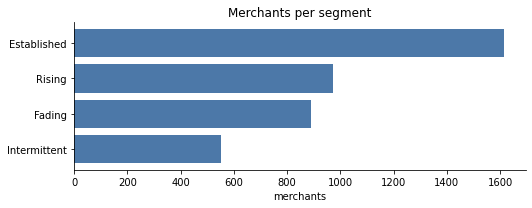

In [3]:
import matplotlib.pyplot as plt

NAMES = {1: "Established", 3: "Rising", 2: "Fading", 0: "Intermittent"}
counts = profile["merchants"]
labels = [f"{NAMES[i]}" for i, _ in counts.index]

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(labels[::-1], counts.values[::-1], color="#4C78A8")
ax.set_xlabel("merchants")
ax.set_title("Merchants per segment")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Where the money is

Segment sizes say little on their own; revenue share is the number that matters.

In [4]:
joined = ranking.merge(behaviour[["merchant_abn", "segment_id", "segment"]], on="merchant_abn")

value = (
    joined.groupby("segment_id")
    .agg(merchants=("merchant_abn", "size"),
         bnpl_revenue=("estimated_bnpl_revenue", "sum"),
         avg_customers=("unique_customers", "mean"),
         txns_per_customer=("transactions_per_customer", "mean"))
)
value["merchant_share"] = value["merchants"] / value["merchants"].sum()
value["revenue_share"] = value["bnpl_revenue"] / value["bnpl_revenue"].sum()
value.index = [NAMES[i] for i in value.index]
value[["merchants", "merchant_share", "revenue_share", "avg_customers", "txns_per_customer"]].round(3)

,merchants,merchant_share,revenue_share,avg_customers,txns_per_customer
Intermittent,551,0.137,0.012,21.450,1.000
Established,1615,0.401,0.881,4734.311,1.215
Fading,889,0.221,0.049,238.286,1.005
Rising,971,0.241,0.058,292.443,1.006


**This table is the argument for segmenting at all.** One segment is 40% of merchants and holds
close to 90% of BNPL revenue. Rank every merchant on one list and the top 100 is drawn almost
entirely from it, leaving three quarters of the base unexamined.

Note also that repeat purchasing barely moves between segments (about 1.0 to 1.2 transactions per
customer). What separates merchants here is **how many customers they have**, not how often those
customers return.

## 4. A ranking system for each segment

The spec asks for the ranking to be curated per segment, so each segment carries its own weights
rather than one global score applied four times.

The weights are not asserted. On the time split — trained on Feb 2021 to Feb 2022, measured
against revenue actually realised Mar to Aug 2022 — every feature was correlated with realised
revenue *within each segment*, and the weights follow that order of predictive power. They live
in `SEGMENT_WEIGHTS` in `scripts/top10_per_segment.py`.

What the evidence said: among Established merchants, breadth of customer base earns real weight
alongside revenue. In the thinner segments almost nothing beyond revenue predicts anything, so
revenue dominates there by default.

In [5]:
from top10_per_segment import SEGMENT_WEIGHTS, load, add_ranks

pd.DataFrame(SEGMENT_WEIGHTS).rename(columns=NAMES).fillna(0).round(3)

,Established,Rising,Fading,Intermittent
estimated_bnpl_revenue,0.70,0.70,0.70,0.70
log_value_growth,0.08,0.08,0.08,0.08
transactions_per_customer,0.04,0.04,0.04,0.04
repeat_rate,0.03,0.03,0.03,0.03
stability,0.03,0.03,0.03,0.03
active_month_ratio,0.02,0.02,0.02,0.02
customer_spread,0.05,0.05,0.05,0.05
customer_income,0.03,0.03,0.03,0.03
customer_irsad,0.02,0.02,0.02,0.02


## 5. Are these segments just product categories?

If merchants of a kind behaved alike, grouping by what they sell would be simpler and this
segmentation would be redundant. `scripts/segment_merchants.py` builds that comparison: the
merchant tags reduce to 25 product categories, grouped into 5 (Technology, Home & Garden, Fashion,
Arts, Leisure). It exists for this check, not as a rival answer.

In [6]:
shop = pd.read_parquet("../data/tables/processed/merchant_segments")[["merchant_abn", "segment"]]
shop = shop.rename(columns={"segment": "shop_type"})

cross = joined.merge(shop, on="merchant_abn", how="left")
share = pd.crosstab(cross["segment_id"], cross["shop_type"], normalize="index") * 100
share.index = [NAMES[i] for i in share.index]
share.round(1)

shop_type,"Arts, Media & Stationery",Fashion & Personal Care,Home & Garden,Leisure & Transport,Technology & Telecom
Intermittent,26.5,14.3,23.2,22.1,13.8
Established,21.4,19.6,20.4,13.1,25.5
Fading,24.3,19.2,20.8,15.1,20.6
Rising,24.0,20.0,19.1,16.8,20.2


Every behaviour segment holds roughly 13–26% of every product category. Performance is therefore
close to independent of what a merchant sells, and grouping by product would not have produced
these distinctions. The one visible tilt is that the least active merchants lean towards Arts and
away from Technology.

That settles the question: **behaviour is the segmentation, product category is the control.**

## 6. The top 10 in each segment

In [7]:
ranked = add_ranks(load())

for seg_id in [1, 3, 2, 0]:
    block = ranked[ranked.segment_id == seg_id]
    top = block.nsmallest(10, "rank_in_segment")
    print(f"\n=== {NAMES[seg_id]}  ({len(block):,} merchants) ===")
    print(
        top[["name", "segment_score", "estimated_bnpl_revenue", "unique_customers",
             "log_value_growth", "rank_overall"]]
        .to_string(index=False, float_format=lambda v: f"{v:,.2f}")
    )


=== Established  (1,615 merchants) ===
                         name  segment_score  estimated_bnpl_revenue  unique_customers  log_value_growth  rank_overall
Dignissim Maecenas Foundation          92.91              624,754.83             22580              0.36             1
     Arcu Sed Eu Incorporated          92.59              457,354.28             19131              0.36             2
            Leo In Consulting          92.57              613,410.60             24081              0.34             3
         Mauris Non Institute          92.37              575,026.05             23914              0.35             4
               Ornare Limited          92.30              579,577.81             17471              0.36             6
     Odio Phasellus Institute          92.28              568,750.95              9090              0.39             5
    Lobortis Ultrices Company          92.11              559,913.72             23875              0.34             7
        

In [8]:
rows = []
for seg_id in [1, 3, 2, 0]:
    block = ranked[ranked.segment_id == seg_id]
    picks = lambda col: set(block.nsmallest(10, col)["merchant_abn"])
    mine = picks("rank_in_segment")
    rows.append({
        "segment": NAMES[seg_id],
        "best merchant's rank on the overall list": int(block["rank_overall"].min()),
        "same picks as global v2": len(mine & picks("rank_in_segment_v2")),
        "same picks as past revenue": len(mine & picks("rank_in_segment_baseline")),
    })
pd.DataFrame(rows).set_index("segment")

,best merchant's rank on the overall list,same picks as global v2,same picks as past revenue
segment,,,
Established,1,9,8
Rising,769,5,1
Fading,1122,4,0
Intermittent,2091,4,1


**Two things to read here.**

The best merchant outside Established sits several hundred places down the overall list. Without
segments, those merchants are never shortlisted.

The three rankings agree closely in the large segment and barely agree in the small ones. The
group's open question — global v2 score or plain past revenue — therefore matters *most* exactly
where the segmentation is doing its work.

## 7. Limitations

1. **The per-segment weights were fitted on the test window**, so the evidence behind them is
   optimistic. They should be refitted on a held-out split before anyone claims they generalise.
2. **Past revenue alone remains a very strong predictor within every segment** (Spearman 0.95+ in
   three of the four), and on top-10 capture it still beats both the global score and these
   weights. Worth stating plainly: the extra machinery buys interpretability and risk awareness,
   not accuracy.
3. **396 merchants trade but have no metadata row** — no category and no take rate, so no segment.
   They account for 580,830 transactions and roughly $202.65M, and are excluded throughout.
4. **Segments are balanced by merchant count, not value.** A top 10 from Intermittent is not
   commercially comparable to a top 10 from Established.
5. **Some merchants have no growth figure** (too little history). They are median-filled before
   clustering and appear as `nan` in the tables.